# Support Vector Machines and the Kernel Trick
### A binary-classification study on a two-spirals dataset

**Goal.** Show how an SVM builds a decision boundary, and how the kernel trick lets it learn a nonlinear pattern that a straight line cannot.

**Plan**
1. Generate and understand the data (and why a line fails)
2. Split once, scale inside a pipeline (no leakage)
3. Compare three SVM families on the *same* split: **Linear** (baseline), **Polynomial** (degrees 2, 3, 5), **RBF** (several gammas). C is tuned for all of them.
4. Choose parameters with 5-fold cross-validation only; touch the test set for reporting, never for choosing
5. Visualise decision boundaries and support vectors
6. Study the kernel trick: what it computes, what it costs, why parameters matter
7. Pick the most suitable model and justify it

**Why spirals?** Two interleaved spiral arms are a classic hard case for linear models, and each kernel behaves differently on them: a global polynomial has to bend many times, while a local RBF kernel can simply follow the arms.

In [1]:
import sys, time, warnings
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics.pairwise import rbf_kernel, polynomial_kernel

from utils import make_spirals, evaluate, timed_fit, n_support, plot_boundary

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#1f5fa8", "#d9661f"   # class colours (colour-blind-safe pair)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. The data

`make_spirals` (in `src/utils.py`) draws points along two spiral arms. Class 1 is class 0 rotated by 180 degrees, then Gaussian noise is added to every point. Two knobs control difficulty: `turns` (how many times the arms wind) and `noise` (how much the arms overlap).

X shape: (600, 2) | classes: {np.int64(0): np.int64(300), np.int64(1): np.int64(300)}
           x1      x2
count  600.00  600.00
mean    -0.02   -0.01
std      4.77    4.71
min    -10.65  -10.74
25%     -3.59   -3.63
50%     -0.08    0.01
75%      3.58    3.80
max     10.73    9.05


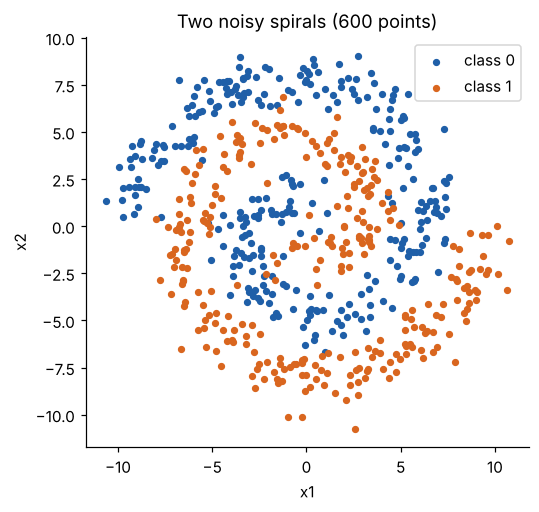

In [2]:
X, y = make_spirals(n_per_class=300, noise=0.8, turns=1.5, seed=SEED)

print("X shape:", X.shape, "| classes:", dict(zip(*np.unique(y, return_counts=True))))
print(pd.DataFrame(X, columns=["x1", "x2"]).describe().round(2))

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(*X[y == 0].T, s=14, c=BLUE, label="class 0")
ax.scatter(*X[y == 1].T, s=14, c=ORANGE, label="class 1")
ax.set_aspect("equal"); ax.legend(); ax.set_title("Two noisy spirals (600 points)")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.show()

### Can a straight line separate these classes?

No. The two classes are rotated copies of each other and both wind around the same centre, so each class has points on *both* sides of almost any line. A quick numerical check: if a line could work, the two class means would be far apart compared with the spread of the data.

In [3]:
m0, m1 = X[y == 0].mean(axis=0), X[y == 1].mean(axis=0)
print("class 0 mean:", m0.round(2), "| class 1 mean:", m1.round(2))
print("distance between class means:", np.linalg.norm(m0 - m1).round(2),
      "| spread (std) of each feature: about", X.std(axis=0).round(2))

class 0 mean: [-0.57  1.95] | class 1 mean: [ 0.53 -1.96]
distance between class means: 4.06 | spread (std) of each feature: about [4.77 4.7 ]


The class means are only about 4 units apart while each feature has a spread of about 4.7, so the classes are barely separated along any single direction. The noise also makes the arms overlap where they pass close together, so even a flexible model should not expect 100%. A linear SVM should stay far from perfect, and the question is how much a kernel helps.

## 2. Split and preprocessing (no leakage)

* One stratified 80/20 split with a fixed seed. **All models use this same split.**
* `StandardScaler` lives *inside* a scikit-learn `Pipeline`. In cross-validation the scaler is refitted on each training fold only, so statistics from the validation fold never leak into training.
* The test set is held out. It is used to **report** each tuned model once. Parameters are chosen from cross-validation scores only.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, np.bincount(y_train), "| test:", X_test.shape, np.bincount(y_test))

# what "fit on training data only" means in numbers
scaler = StandardScaler().fit(X_train)
print("scaler mean (train only):   ", scaler.mean_.round(3))
print("mean of ALL data (leakage): ", X.mean(axis=0).round(3))

train: (480, 2) [240 240] | test: (120, 2) [60 60]
scaler mean (train only):    [ 0.001 -0.075]
mean of ALL data (leakage):  [-0.018 -0.005]


## 3. Experiment design

| Item | Choice | Reason |
|---|---|---|
| Model | `make_pipeline(StandardScaler(), SVC(kernel=...))` | scaling matters for distance-based kernels; pipeline prevents leakage |
| Selection | `GridSearchCV`, `StratifiedKFold(5, shuffle=True)` | each parameter set is trained on 4 folds and scored on the 5th; class balance is kept in every fold |
| Selection metric | balanced accuracy | robust if classes were imbalanced (here they are balanced, so it matches accuracy) |
| C grid | 0.01, 0.1, 1, 10, 100 | log-spaced, same for all three kernels |
| Polynomial | degree in {2, 3, 5}, `coef0=1`, `gamma='scale'` | `coef0=1` includes all lower-order terms; each degree is tuned separately over C |
| RBF | gamma in {0.01, 0.1, 0.5, 1, 2, 5, 10, 50} | log-spaced from very smooth to very local |
| Reporting | accuracy, balanced accuracy, F1, confusion matrix on the untouched test set | |

`GridSearchCV` refits the best parameters on the whole training set (`refit=True`), and that refitted model is what we evaluate on the test set.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = "balanced_accuracy"
C_GRID = [0.01, 0.1, 1, 10, 100]
GAMMA_GRID = [0.01, 0.1, 0.5, 1, 2, 5, 10, 50]

def run_search(kernel, grid):
    pipe = make_pipeline(StandardScaler(), SVC(kernel=kernel, max_iter=1_000_000))
    gs = GridSearchCV(pipe, grid, scoring=SCORING, cv=cv, n_jobs=-1, return_train_score=True)
    return gs.fit(X_train, y_train)

def cv_table(gs, cols):
    # compact view of the CV results (mean validation score per parameter set)
    r = pd.DataFrame(gs.cv_results_)
    out = r[[f"param_svc__{c}" for c in cols] + ["mean_train_score", "mean_test_score", "std_test_score"]].copy()
    out.columns = cols + ["train_bal_acc", "cv_bal_acc", "cv_std"]
    return out.round(3)

## 4. Linear SVM (baseline)

In [6]:
gs_lin = run_search("linear", {"svc__C": C_GRID})
print("best:", gs_lin.best_params_, "| CV balanced accuracy:", round(gs_lin.best_score_, 3))
cv_table(gs_lin, ["C"])

best: {'svc__C': 0.1} | CV balanced accuracy: 0.66


,C,train_bal_acc,cv_bal_acc,cv_std
0,0.01,0.661,0.654,0.020
1,0.10,0.666,0.660,0.014
2,1.00,0.666,0.658,0.012
3,10.00,0.666,0.656,0.009
4,100.00,0.666,0.656,0.009


Look at the `cv_bal_acc` column: it barely moves as C changes. When the *representation* is wrong, regularisation cannot fix it. This is the baseline the kernels have to beat.

## 5. Polynomial-kernel SVM

$k(x,z) = (\gamma\, x^\top z + c_0)^d$. Each degree is tuned over C separately, so the degrees are compared at their best C.

In [7]:
DEGREES = [2, 3, 5]
gs_poly = {}
for d in DEGREES:
    gs_poly[d] = run_search("poly", {"svc__degree": [d], "svc__C": C_GRID,
                                     "svc__coef0": [1], "svc__gamma": ["scale"]})
    print(f"degree {d}: best C = {gs_poly[d].best_params_['svc__C']}, "
          f"CV balanced accuracy = {gs_poly[d].best_score_:.3f}")

degree 2: best C = 0.01, CV balanced accuracy = 0.652


degree 3: best C = 10, CV balanced accuracy = 0.819


degree 5: best C = 10, CV balanced accuracy = 0.948


In [8]:
pd.concat({f"degree {d}": cv_table(gs_poly[d], ["C"]).set_index("C") for d in DEGREES}, axis=1)

degree 2                        degree 3                        degree 5                  
       train_bal_acc cv_bal_acc cv_std train_bal_acc cv_bal_acc cv_std train_bal_acc cv_bal_acc cv_std
C                                                                                                     
0.01           0.658      0.652  0.018         0.648      0.642  0.025         0.736      0.704  0.036
0.10           0.641      0.627  0.046         0.742      0.719  0.040         0.851      0.842  0.020
1.00           0.645      0.621  0.048         0.819      0.800  0.015         0.922      0.912  0.024
10.00          0.644      0.627  0.054         0.831      0.819  0.014         0.957      0.948  0.021
100.00         0.644      0.627  0.054         0.831      0.819  0.017         0.969      0.944  0.019

## 6. RBF-kernel SVM

$k(x,z) = \exp(-\gamma\,\lVert x-z\rVert^2)$. Here C and gamma are tuned **together** on a grid, because they interact: a large gamma makes the model flexible, and a large C lets it act on that flexibility.

In [9]:
gs_rbf = run_search("rbf", {"svc__C": C_GRID, "svc__gamma": GAMMA_GRID})
print("best:", gs_rbf.best_params_, "| CV balanced accuracy:", round(gs_rbf.best_score_, 3))

# CV balanced accuracy for every (C, gamma): rows = C, columns = gamma
r = pd.DataFrame(gs_rbf.cv_results_)
r["C"], r["gamma"] = r["param_svc__C"].astype(float), r["param_svc__gamma"].astype(float)
r.pivot(index="C", columns="gamma", values="mean_test_score").round(3)

best: {'svc__C': 1, 'svc__gamma': 2} | CV balanced accuracy: 0.958


gamma,0.01,0.10,0.50,1.00,2.00,5.00,10.00,50.00
C,,,,,,,,
0.01,0.646,0.654,0.650,0.677,0.827,0.929,0.952,0.892
0.10,0.646,0.660,0.646,0.750,0.900,0.942,0.950,0.892
1.00,0.658,0.627,0.827,0.929,0.958,0.952,0.935,0.921
10.00,0.658,0.735,0.927,0.952,0.948,0.950,0.938,0.915
100.00,0.627,0.812,0.952,0.944,0.950,0.921,0.894,0.906


## 7. Comparison on the untouched test set

For each tuned model we report the chosen parameters, cross-validation score (how it was selected), and test metrics. `n_sv` is the number of support vectors, and `fit_time_s` is the time to refit on the 480 training points.

In [10]:
searches = {"Linear": gs_lin, **{f"Poly d={d}": gs_poly[d] for d in DEGREES}, "RBF": gs_rbf}

rows, confs = [], {}
for name, gs in searches.items():
    best = gs.best_estimator_
    te, tr = evaluate(best, X_test, y_test), evaluate(best, X_train, y_train)
    _, fit_s = timed_fit(clone(best), X_train, y_train)
    i = gs.best_index_
    rows.append(dict(
        model=name,
        params={k.replace("svc__", ""): v for k, v in gs.best_params_.items() if k != "svc__gamma" or name == "RBF"},
        cv_bal_acc=gs.best_score_, cv_std=gs.cv_results_["std_test_score"][i],
        train_acc=tr["accuracy"], test_acc=te["accuracy"],
        test_bal_acc=te["balanced_acc"], test_f1=te["f1"],
        n_sv=n_support(best), fit_time_s=fit_s))
    confs[name] = te["confusion"]

results = pd.DataFrame(rows).set_index("model")
results.round(3)

,params,cv_bal_acc,cv_std,train_acc,test_acc,test_bal_acc,test_f1,n_sv,fit_time_s
model,,,,,,,,,
Linear,{'C': 0.1},0.660,0.014,0.660,0.625,0.625,0.622,354,0.005
Poly d=2,"{'C': 0.01, 'coef0': 1, 'degree': 2}",0.652,0.018,0.665,0.625,0.625,0.615,396,0.005
Poly d=3,"{'C': 10, 'coef0': 1, 'degree': 3}",0.819,0.014,0.831,0.850,0.850,0.842,211,0.011
Poly d=5,"{'C': 10, 'coef0': 1, 'degree': 5}",0.948,0.021,0.958,0.933,0.933,0.930,107,0.011
RBF,"{'C': 1, 'gamma': 2}",0.958,0.015,0.962,0.950,0.950,0.950,165,0.004


**How much to trust small differences.** The test set has 120 points, so one test point is 0.8 percentage points, and a 95% interval around a 0.95 accuracy is several points wide. The fold-to-fold standard deviation of the CV score (`cv_std`) is also 1 to 2 points. Gaps of one or two points, such as polynomial degree 5 versus RBF, are therefore within noise. The large gaps (linear and degree 2 versus the rest) are not.

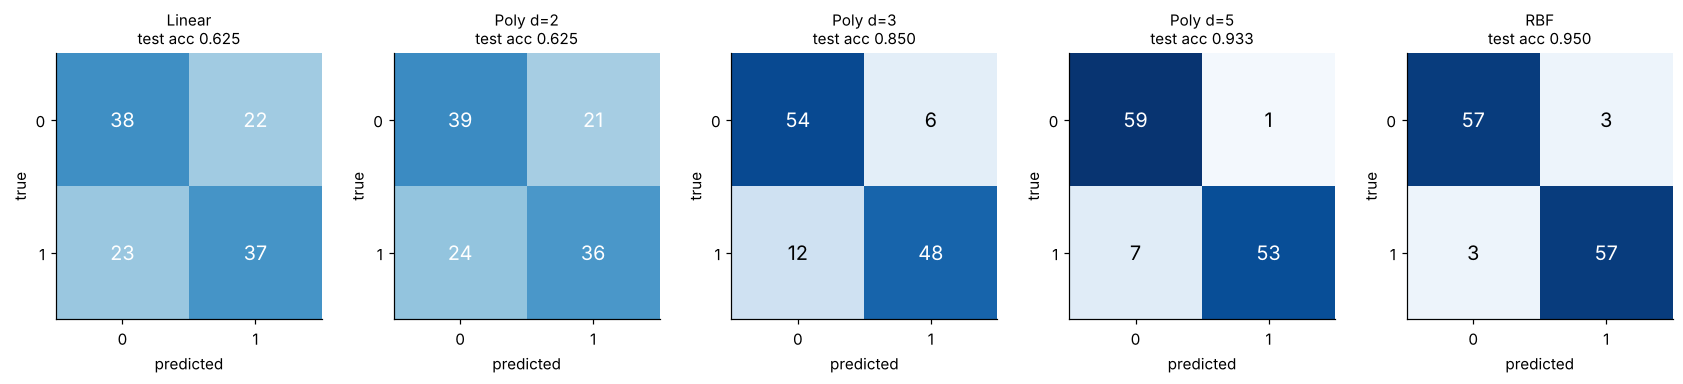

In [11]:
fig, axes = plt.subplots(1, len(confs), figsize=(3.1 * len(confs), 3.2))
for ax, (name, cm) in zip(axes, confs.items()):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum(axis=1).max())
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=13,
                color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{name}\ntest acc {results.loc[name, 'test_acc']:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

## 8. Decision boundaries and support vectors

Black circles mark support vectors (the training points that touch or violate the margin). The solid black line is the decision boundary. Support vectors are stored in scaled space, so `plot_boundary` maps them back to the original coordinates with the scaler's `inverse_transform`.

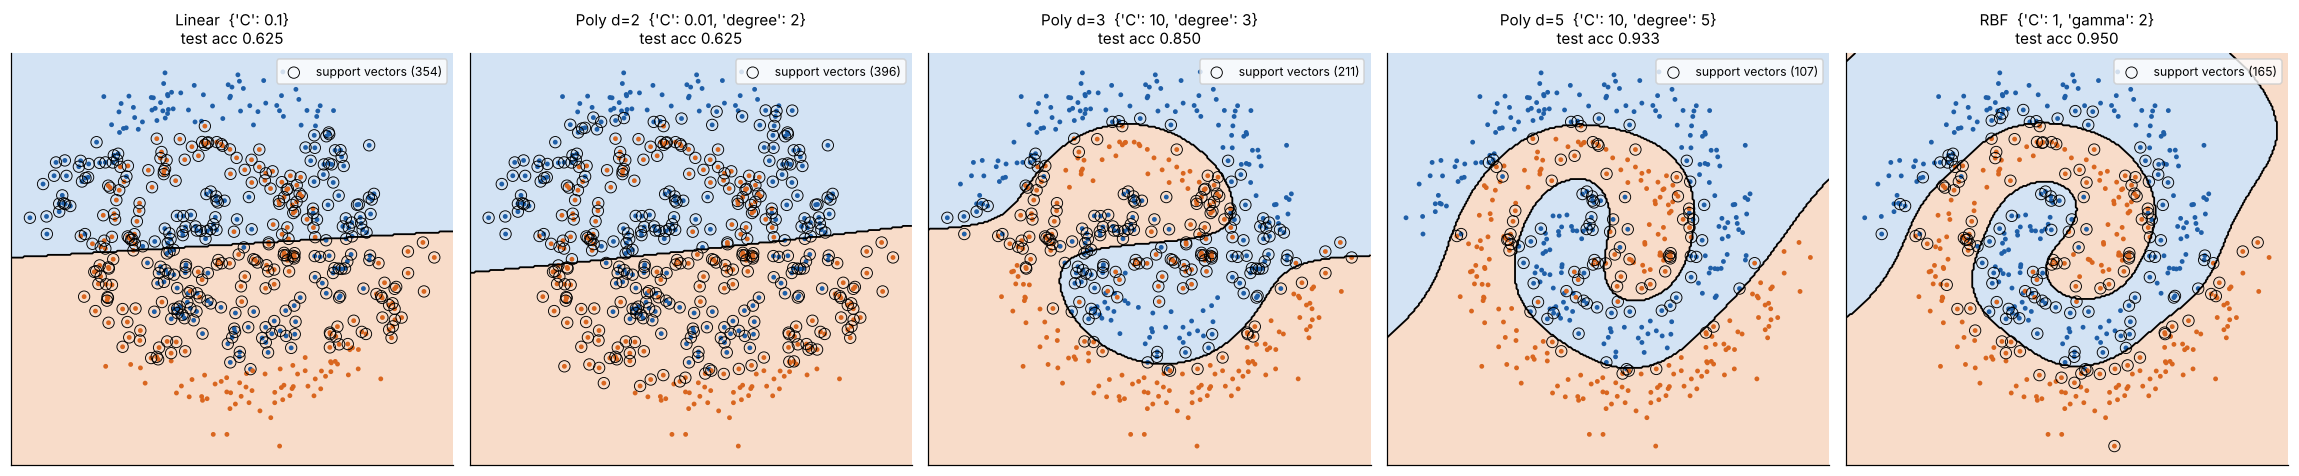

In [12]:
fig, axes = plt.subplots(1, len(searches), figsize=(4.2 * len(searches), 4.4))
for ax, (name, gs) in zip(axes, searches.items()):
    p = {k.replace("svc__", ""): v for k, v in gs.best_params_.items() if k not in ("svc__coef0", "svc__gamma")}
    if name == "RBF":
        p["gamma"] = gs.best_params_["svc__gamma"]
    plot_boundary(gs.best_estimator_, X_train, y_train, ax=ax,
                  title=f"{name}  {p}\ntest acc {results.loc[name, 'test_acc']:.3f}")
plt.tight_layout(); plt.show()

## 9. Parameter sensitivity

### 9.1 Effect of C (all kernels)

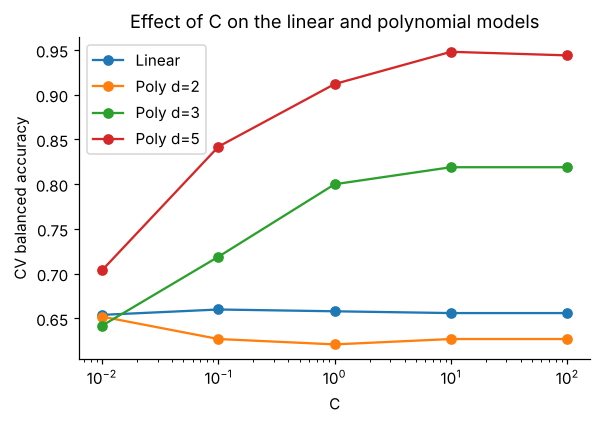

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for name, gs in searches.items():
    if name == "RBF":
        continue   # RBF depends on gamma as well, see the heatmap below
    t = cv_table(gs, ["C"])
    ax.plot(t["C"].astype(float), t["cv_bal_acc"], marker="o", label=name)
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("CV balanced accuracy")
ax.set_title("Effect of C on the linear and polynomial models"); ax.legend()
plt.show()

### 9.2 RBF: C and gamma together

Left: training score. Right: cross-validation score. Where the left panel is high and the right panel is low, the model has memorised the training folds (overfitting).

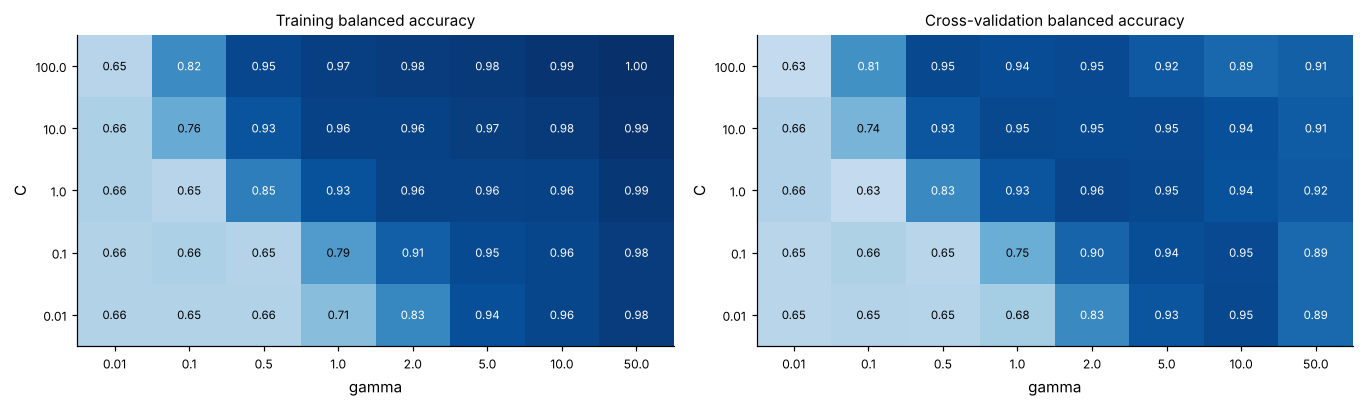

In [14]:
def heat(ax, M, title):
    im = ax.imshow(M.values, origin="lower", cmap="Blues", vmin=0.5, vmax=1.0, aspect="auto")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for (i, j), v in np.ndenumerate(M.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if v > 0.8 else "black")
    ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
heat(axes[0], r.pivot(index="C", columns="gamma", values="mean_train_score"), "Training balanced accuracy")
heat(axes[1], r.pivot(index="C", columns="gamma", values="mean_test_score"), "Cross-validation balanced accuracy")
plt.tight_layout(); plt.show()

### 9.3 Under-fit, selected, over-fit

Top row: vary gamma at the selected C. Bottom row: vary C at the selected gamma. Titles show training and test accuracy; a large gap signals overfitting.

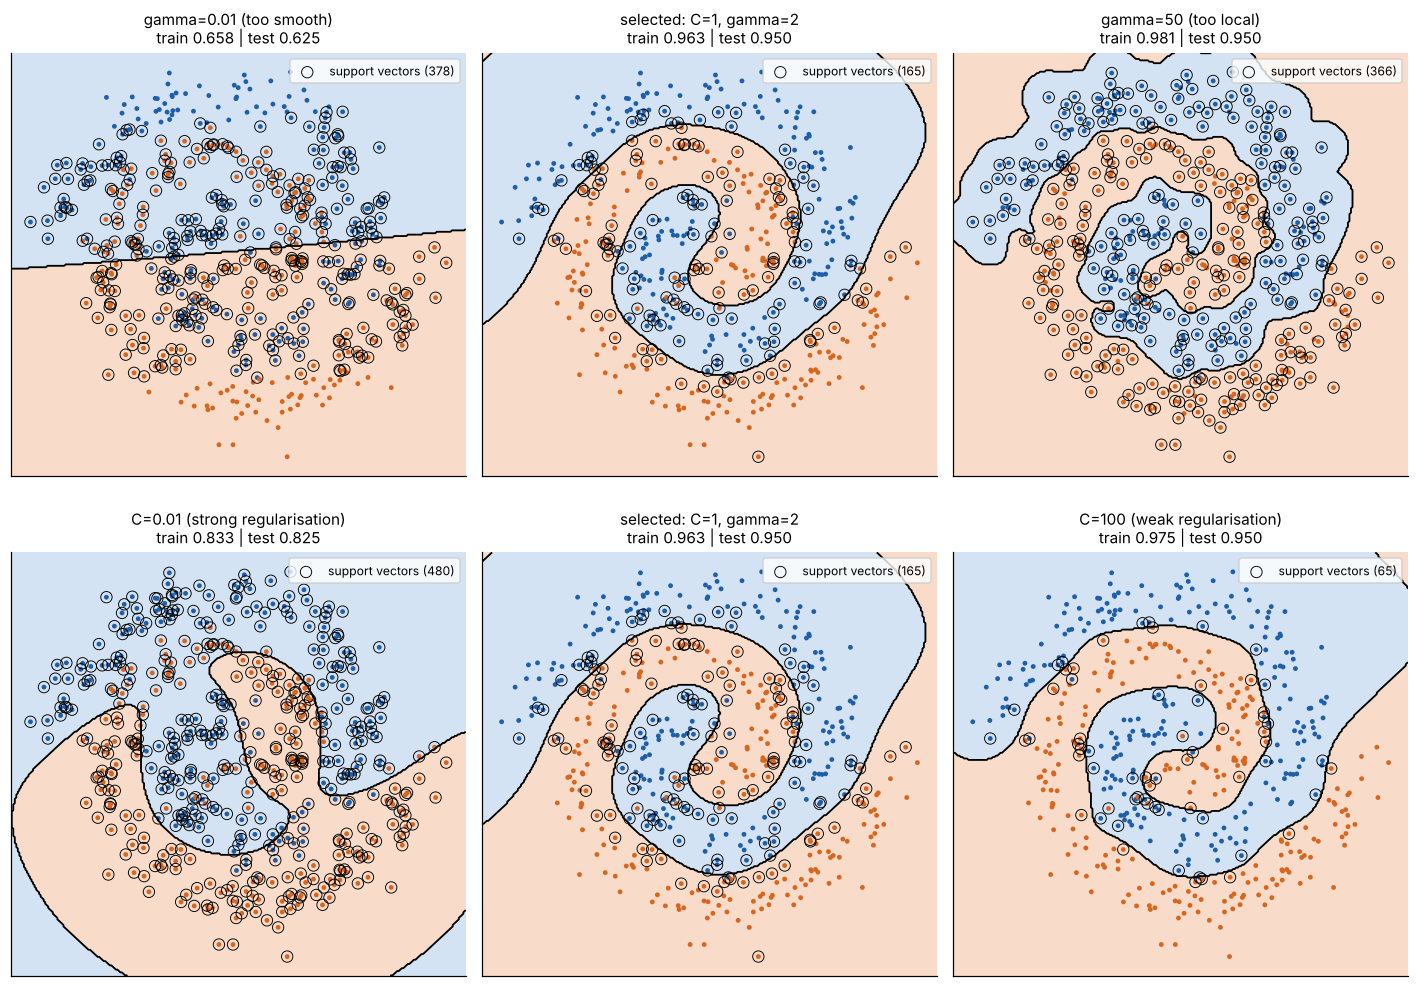

In [15]:
bC, bG = gs_rbf.best_params_["svc__C"], gs_rbf.best_params_["svc__gamma"]
panels = [
    [("gamma=0.01 (too smooth)", dict(C=bC, gamma=0.01)),
     (f"selected: C={bC}, gamma={bG}", dict(C=bC, gamma=bG)),
     ("gamma=50 (too local)", dict(C=bC, gamma=50))],
    [("C=0.01 (strong regularisation)", dict(C=0.01, gamma=bG)),
     (f"selected: C={bC}, gamma={bG}", dict(C=bC, gamma=bG)),
     ("C=100 (weak regularisation)", dict(C=100, gamma=bG))],
]
fig, axes = plt.subplots(2, 3, figsize=(13, 9.2))
for row, axrow in zip(panels, axes):
    for (label, p), ax in zip(row, axrow):
        m = make_pipeline(StandardScaler(), SVC(kernel="rbf", **p)).fit(X_train, y_train)
        tr, te = m.score(X_train, y_train), m.score(X_test, y_test)
        plot_boundary(m, X_train, y_train, ax=ax, title=f"{label}\ntrain {tr:.3f} | test {te:.3f}")
plt.tight_layout(h_pad=3.0); plt.show()

What the panels show:

* **Gamma too small (top left)**: the boundary is almost a straight line, so the model under-fits (train 0.66). Every point's influence reaches across the whole plane.
* **Gamma too large (top right)**: the boundary hugs individual points and breaks into small islands, with more than twice as many support vectors as the selected model. Training accuracy goes up while the cross-validation score in the heatmap drops (0.92 at C=1, gamma=50). On this 120-point test set the damage is not visible, because one point is worth 0.8 percentage points, so cross-validation is the more reliable signal here.
* **C too small (bottom left)**: strong regularisation gives a smooth boundary that cannot follow the arms (train 0.83), and *every* training point becomes a support vector (480). With a wide margin, all points are inside it.
* **C large (bottom right)**: violations are expensive, so the margin narrows and only 65 points remain support vectors. Accuracy is still good at gamma=2, but the boundary is more irregular. The selected C=1 was picked by cross-validation, which scored it a little higher than C=100 (0.958 vs 0.950).

### 9.4 Validation curve over gamma (selected C)

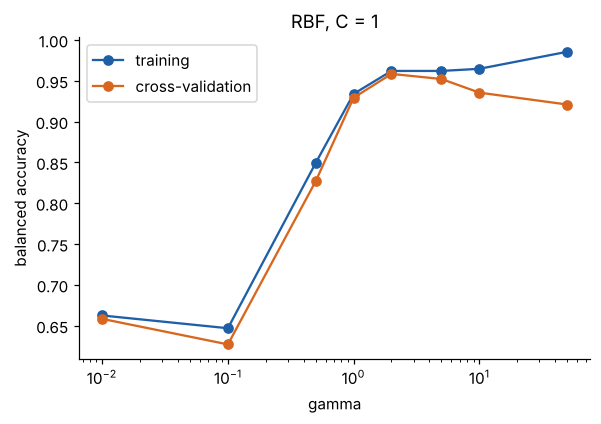

In [16]:
sub = r[r["C"] == float(bC)].sort_values("gamma")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(sub["gamma"], sub["mean_train_score"], marker="o", color=BLUE, label="training")
ax.plot(sub["gamma"], sub["mean_test_score"], marker="o", color=ORANGE, label="cross-validation")
ax.set_xscale("log"); ax.set_xlabel("gamma"); ax.set_ylabel("balanced accuracy")
ax.set_title(f"RBF, C = {bC}"); ax.legend()
plt.show()

## 10. The Kernel Trick

### 10.1 The idea
A linear SVM works on dot products $x_i^\top x_j$. If we map the data with $\phi$ into a richer feature space, a straight line there can look like a curve in the original space. The **dual** form of the SVM only uses the data through dot products, so we can replace

$$x_i^\top x_j \;\longrightarrow\; k(x_i, x_j) = \phi(x_i)^\top \phi(x_j)$$

and never build $\phi(x)$. The decision function becomes

$$f(x) = \sum_{i \in \text{SV}} \alpha_i y_i\, k(x_i, x) + b .$$

The next cells prove each of these claims numerically.

### 10.2 A kernel equals a dot product in feature space
For $x,z\in\mathbb{R}^2$: $(x^\top z)^2 = \phi(x)^\top\phi(z)$ with $\phi(x) = (x_1^2,\ \sqrt2\,x_1x_2,\ x_2^2)$.

In [17]:
def phi2(v):
    return np.array([v[0] ** 2, np.sqrt(2) * v[0] * v[1], v[1] ** 2])

rng = np.random.default_rng(SEED)
pairs = rng.normal(size=(1000, 2, 2))
kernel_side = np.array([(a @ b) ** 2 for a, b in pairs])          # computed in 2-D
feature_side = np.array([phi2(a) @ phi2(b) for a, b in pairs])    # computed in 3-D
print("max |difference| over 1000 random pairs:", np.abs(kernel_side - feature_side).max())

# sklearn's polynomial kernel is the same thing
a, b = pairs[0]
print("sklearn polynomial_kernel:", polynomial_kernel(a[None], b[None], degree=2, gamma=1, coef0=0)[0, 0].round(6),
      "| (a.b)^2:", ((a @ b) ** 2).round(6))

max |difference| over 1000 random pairs: 7.105427357601002e-15
sklearn polynomial_kernel: 0.561746 | (a.b)^2: 0.561746


### 10.3 An SVM on explicit features gives the same model as the kernel SVM
Use $k(x,z) = (x^\top z + 1)^2$. Its explicit feature map is $\phi(x) = (1,\ \sqrt2 x_1,\ \sqrt2 x_2,\ x_1^2,\ \sqrt2 x_1x_2,\ x_2^2)$. We train (a) a *linear* SVM on the explicit 6-dimensional features and (b) a *kernel* SVM on the original 2-D data. The kernel version never builds the features.

In [18]:
def phi_explicit(Z):
    x1, x2 = Z[:, 0], Z[:, 1]
    return np.c_[np.ones(len(Z)), np.sqrt(2) * x1, np.sqrt(2) * x2, x1 ** 2, np.sqrt(2) * x1 * x2, x2 ** 2]

sc = StandardScaler().fit(X_train)
Ztr, Zte = sc.transform(X_train), sc.transform(X_test)

explicit = SVC(kernel="linear", C=10).fit(phi_explicit(Ztr), y_train)
kernel = SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=10).fit(Ztr, y_train)

d_exp = explicit.decision_function(phi_explicit(Zte))
d_ker = kernel.decision_function(Zte)
print("max |decision-function difference|:", f"{np.abs(d_exp - d_ker).max():.2e}")
print("predictions identical on test set :", np.mean(explicit.predict(phi_explicit(Zte)) == kernel.predict(Zte)))
print("support vectors (explicit, kernel):", explicit.n_support_.sum(), kernel.n_support_.sum())

max |decision-function difference|: 2.71e-10
predictions identical on test set : 1.0
support vectors (explicit, kernel): 348 348


The two models agree (up to the solver's stopping tolerance). The kernel computed the same similarities without ever creating the 6-D features.

### 10.4 Rebuilding the RBF prediction from the dual coefficients
Scikit-learn stores $\alpha_i y_i$ in `dual_coef_` and the support vectors in `support_vectors_`. We recompute $f(x)=\sum_i \alpha_i y_i\,k(x_i,x)+b$ by hand and compare with `decision_function`.

In [19]:
best_rbf = gs_rbf.best_estimator_
svc, sc_rbf = best_rbf.named_steps["svc"], best_rbf.named_steps["standardscaler"]
Zt = sc_rbf.transform(X_test)

K = rbf_kernel(Zt, svc.support_vectors_, gamma=svc.gamma)       # (n_test, n_support)
f_manual = K @ svc.dual_coef_.ravel() + svc.intercept_[0]
print("max |manual - decision_function|:", np.abs(f_manual - best_rbf.decision_function(X_test)).max())

# what the dual coefficients say about each point (KKT conditions)
a = np.abs(svc.dual_coef_.ravel())
C_ = svc.C
at_bound = np.isclose(a, C_)
print(f"\n{len(a)} support vectors out of {len(X_train)} training points ({len(a)/len(X_train):.0%})")
print(f"  alpha = C   (inside the margin or misclassified): {at_bound.sum()}")
print(f"  0 < alpha < C (exactly on the margin edge)      : {(~at_bound).sum()}")
print(f"  alpha = 0   (not support vectors, no influence)  : {len(X_train) - len(a)}")

max |manual - decision_function|: 1.1102230246251565e-14

165 support vectors out of 480 training points (34%)
  alpha = C   (inside the margin or misclassified): 135
  0 < alpha < C (exactly on the margin edge)      : 30
  alpha = 0   (not support vectors, no influence)  : 315


### 10.5 What gamma does to the similarity
The RBF kernel is a similarity that equals 1 at distance 0 and decays with distance. Gamma sets how quickly. Large gamma means each support vector only matters very close to itself.

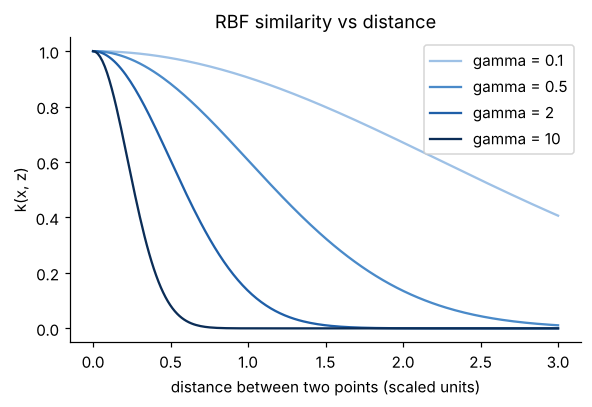

In [20]:
d = np.linspace(0, 3, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
for g, c in zip([0.1, 0.5, 2, 10], ["#9ec1e6", "#4a8ac9", BLUE, "#0b2d57"]):
    ax.plot(d, np.exp(-g * d ** 2), color=c, label=f"gamma = {g}")
ax.set_xlabel("distance between two points (scaled units)"); ax.set_ylabel("k(x, z)")
ax.set_title("RBF similarity vs distance"); ax.legend()
plt.show()

### 10.6 Limitations: dimension of the implicit space, and cost

**Size of the implicit feature space.** A polynomial kernel of degree $d$ on $p$ inputs corresponds to $\binom{p+d}{d}$ features. The RBF kernel corresponds to an *infinite*-dimensional $\phi$. Building these explicitly would be impossible, while the kernel only needs a dot product in $\mathbb{R}^p$.

In [21]:
from math import comb
print("features needed by an explicit polynomial map (with all lower-order terms):")
print(pd.DataFrame({p: {d: comb(p + d, d) for d in (2, 3, 5)} for p in (2, 100, 1000)})
      .rename_axis("degree").rename(columns=lambda p: f"p={p} inputs").map("{:,}".format))

features needed by an explicit polynomial map (with all lower-order terms):
       p=2 inputs p=100 inputs      p=1000 inputs
degree                                           
2               6        5,151            501,501
3              10      176,851        167,668,501
5              21   96,560,646  8,459,043,543,951


**Training and prediction cost.** The kernel SVM works with the $n \times n$ Gram matrix of pairwise similarities, so memory and time grow quickly with the number of samples $n$ (libsvm training is roughly between $O(n^2)$ and $O(n^3)$ in practice). Prediction costs one kernel evaluation per support vector, so models with many support vectors are slower. We measure this on larger spiral samples (same parameters for every size).

In [22]:
KERNELS = {"linear": dict(kernel="linear", C=1),
           "poly d=3": dict(kernel="poly", degree=3, coef0=1, C=10),
           "rbf": dict(kernel="rbf", C=1, gamma=2)}
SIZES = [250, 500, 1000, 2000, 4000, 8000]

recs = []
for n in SIZES:
    Xn, yn = make_spirals(n // 2, noise=0.8, turns=1.5, seed=SEED)
    for name, params in KERNELS.items():
        pipe = make_pipeline(StandardScaler(), SVC(max_iter=2_000_000, **params))
        pipe, fit_s = timed_fit(pipe, Xn, yn)
        t0 = time.perf_counter(); pipe.predict(Xn[:1000]); pred_s = time.perf_counter() - t0
        recs.append(dict(n=n, kernel=name, fit_s=fit_s, predict_1000_s=pred_s, n_sv=n_support(pipe)))
scale = pd.DataFrame(recs)
scale.pivot(index="n", columns="kernel", values="fit_s").round(3)

kernel,linear,poly d=3,rbf
n,,,
250,0.006,0.007,0.005
500,0.010,0.014,0.007
1000,0.020,0.033,0.009
2000,0.086,0.125,0.023
4000,0.391,0.555,0.077
8000,1.749,2.528,0.215


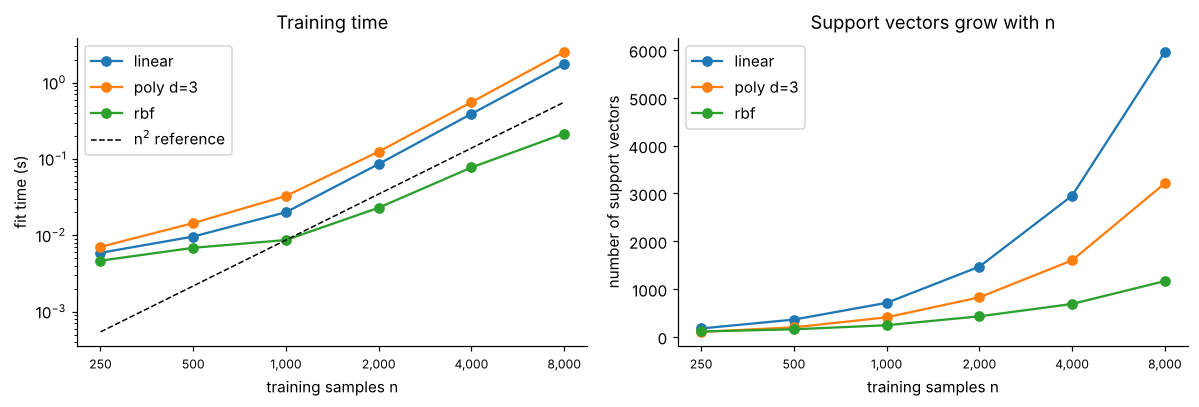

linear    fit time grows like n^2.15 | support vectors at n=8000: 5,961 (75% of the data)
poly d=3  fit time grows like n^2.09 | support vectors at n=8000: 3,212 (40% of the data)
rbf       fit time grows like n^1.54 | support vectors at n=8000: 1,167 (15% of the data)
Gram matrix for n= 10,000: 0.8 GB (float64)
Gram matrix for n=100,000: 80.0 GB (float64)


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name in KERNELS:
    s = scale[scale.kernel == name]
    axes[0].plot(s.n, s.fit_s, marker="o", label=name)
    axes[1].plot(s.n, s.n_sv, marker="o", label=name)
ref = scale[scale.kernel == "rbf"].set_index("n").fit_s
axes[0].plot(SIZES, ref[1000] * (np.array(SIZES) / 1000) ** 2, "k--", lw=1, label="n$^2$ reference")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("training samples n"); ax.legend()
    ax.set_xticks(SIZES); ax.set_xticklabels([f"{s:,}" for s in SIZES], fontsize=8)
    ax.minorticks_off()
axes[0].set_yscale("log"); axes[0].set_ylabel("fit time (s)"); axes[0].set_title("Training time")
axes[1].set_ylabel("number of support vectors"); axes[1].set_title("Support vectors grow with n")
plt.tight_layout(); plt.show()

# empirical growth exponent between n=1000 and n=8000: time ~ n^p
for name in KERNELS:
    s = scale[scale.kernel == name].set_index("n")
    p = np.log(s.fit_s[8000] / s.fit_s[1000]) / np.log(8000 / 1000)
    print(f"{name:9s} fit time grows like n^{p:.2f} | support vectors at n=8000: {s.n_sv[8000]:,} ({s.n_sv[8000]/8000:.0%} of the data)")

for n in (10_000, 100_000):
    print(f"Gram matrix for n={n:>7,}: {n * n * 8 / 1e9:,.1f} GB (float64)")

**What the timing shows.** Fit time grows faster than linearly for every kernel: roughly like $n^{1.5}$ to $n^{1.6}$ for RBF and between $n^{2}$ and $n^{2.3}$ for the degree-3 polynomial and the linear kernel, between 1,000 and 8,000 samples (the exact exponents printed above vary a little from run to run). The number of support vectors also grows with $n$, and prediction cost grows with it. The Gram matrix for 100,000 samples would need about 80 GB in float64, which is why kernel SVMs are used on thousands to tens of thousands of samples, not millions.

One result that may look surprising: on this data the *linear* SVM is the slowest to train and keeps 75% of the points as support vectors. A kernel is not automatically more expensive. The linear model cannot fit these overlapping spirals, so most points violate its margin, and the solver has to keep adjusting many multipliers that sit at the bound C. (This is my reading of why; the measurement itself is the table above.) The cost of a kernel SVM depends on how well the model fits the data, not only on the kernel formula.

### 10.7 Why parameter selection matters
The experiments above show the kernel trick is not a free upgrade. It replaces the question "which line?" by "which notion of similarity?", and the answer is controlled by a few parameters:

* **C** sets how costly margin violations are (small = wide margin, more violations; large = narrow margin that follows the data).
* **degree** sets how many bends a polynomial boundary can make.
* **gamma** sets how local the RBF similarity is.

Poor values give either an under-fit boundary or one that wraps around individual noisy points (section 9.3). Scaling is part of the kernel too: both $x^\top z$ and $\lVert x-z\rVert^2$ are dominated by the largest-scale feature, so the scaler stays inside the pipeline.

## 11. Model selection

The rule is fixed **before** looking at the test numbers and uses cross-validation only:

1. Find the best CV balanced accuracy among the tuned models.
2. Keep every model whose CV score is within **one standard error** of the best (the differences below that are not distinguishable from fold-to-fold noise).
3. Among those, choose the one with the **fewest support vectors** (a simpler, faster, more compact model); break ties by fit time.

In [24]:
k = cv.get_n_splits()
best_cv = results.cv_bal_acc.max()
se = results.loc[results.cv_bal_acc.idxmax(), "cv_std"] / np.sqrt(k)
threshold = best_cv - se

cand = results[results.cv_bal_acc >= threshold].sort_values(["n_sv", "fit_time_s"])
chosen = cand.index[0]
print(f"best CV score = {best_cv:.3f}, one standard error = {se:.3f} -> threshold {threshold:.3f}")
print("models within one standard error:", list(cand.index))
print("\nCHOSEN MODEL:", chosen)
results.loc[[chosen]].round(3)

best CV score = 0.958, one standard error = 0.007 -> threshold 0.952
models within one standard error: ['RBF']

CHOSEN MODEL: RBF


,params,cv_bal_acc,cv_std,train_acc,test_acc,test_bal_acc,test_f1,n_sv,fit_time_s
model,,,,,,,,,
RBF,"{'C': 1, 'gamma': 2}",0.958,0.015,0.962,0.95,0.95,0.95,165,0.004


## 12. Conclusion

**Selected model: RBF SVM with C = 1 and gamma = 2.**

**Why this one**
* It has the best cross-validation balanced accuracy (0.958, standard deviation 0.015 across folds) and is the only model inside one standard error of the best, so the selection rule from section 11 picks it without looking at the test set.
* On the untouched test set it scores accuracy 0.950, balanced accuracy 0.950 and F1 0.950 (6 mistakes out of 120, split evenly between the classes).
* It has one local parameter (gamma) to tune, and the heatmap shows a broad region of good (C, gamma) pairs rather than a single lucky spot.

**The progression across the kernels (test accuracy)**

| Model | Test accuracy | What happened |
|---|---|---|
| Linear | 0.625 | A straight line cannot separate classes that wind around each other. C had almost no effect (CV 0.65 to 0.66). |
| Polynomial, degree 2 | 0.625 | A single curve with one bend gives no benefit over a line on this data. |
| Polynomial, degree 3 | 0.850 | Enough bends to start following the arms. |
| Polynomial, degree 5 | 0.933 | Follows the arms well, with fewer support vectors (107) than RBF (165). |
| RBF | 0.950 | A local similarity follows the arms wherever they go. |

**An honest caveat.** Degree 5 is a close competitor: its CV score (0.948) is within one fold-to-fold standard deviation of RBF's (0.958), and its test accuracy is only two test points lower. Our one-standard-error rule picks RBF, but a different rule (for example, "fewest support vectors within one standard deviation") would pick degree 5. We prefer RBF because it has the highest CV score, because degree 5 is the largest degree we tried (we did not test whether degree 6 or 7 would keep improving, so the degree itself is a parameter that needs a wider search), and because the RBF region of good parameters is broad. With only 120 test points, no choice between these two can be justified by the test score alone.

**What the experiments showed about the Kernel Trick**
1. *It is real, not a metaphor.* A kernel value equals a dot product in feature space (difference about 1e-14), a linear SVM on the explicit features gives the same model as the kernel SVM on the raw inputs, and the RBF prediction can be rebuilt by hand from the support vectors and dual coefficients (difference about 1e-14).
2. *It avoids building the features.* The explicit space for a degree-5 polynomial on 1,000 inputs has more than 8 trillion dimensions, and the RBF space is infinite, yet the kernel only needs dot products of the original inputs.
3. *It has a cost.* Fit time grew roughly like n^1.5 to n^1.6 (RBF) and n^2 to n^2.3 (polynomial, linear) between 1,000 and 8,000 samples, support vectors grow with n, and the Gram matrix for 100,000 samples would need about 80 GB.
4. *Parameters decide everything.* Gamma too small under-fits (train 0.66), gamma too large builds islands around single points (train about 0.99 versus CV 0.92), and C trades margin width against violations (all 480 points become support vectors at C = 0.01). Tuning C alone could not rescue the linear model, because its problem was the representation, not the regularisation.

**Limitations.** The data is synthetic; all models share one split of 480 training and 120 test points; the polynomial models were tuned over C and degree but not gamma or coef0; and the timing numbers depend on this machine.